In [4]:
import pandas as pd
import numpy as np
import seaborn as sns

In [34]:
df = pd.read_csv('credit_risk_dataset.csv')
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


<Axes: xlabel='person_age', ylabel='Count'>

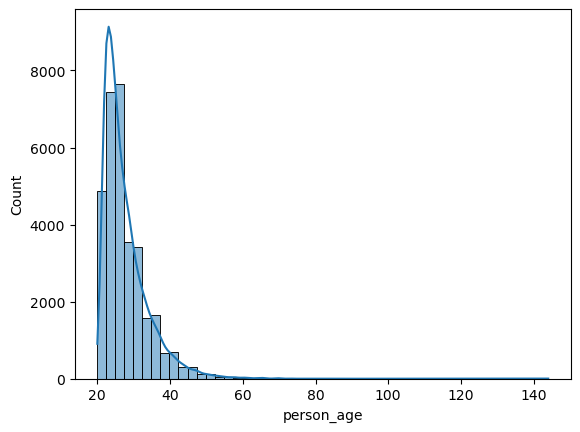

In [62]:
sns.histplot(df['person_age'], bins = 50, kde = True)

<Axes: ylabel='person_age'>

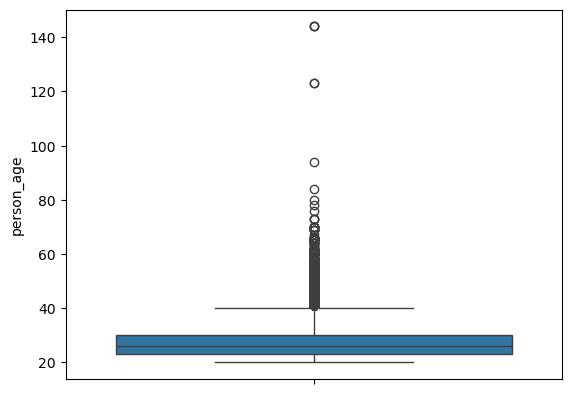

In [58]:
sns.boxplot(df['person_age'])

In [161]:
#df['person_age'].max() тут я решил проверить outliers, оказалось, что есть значения больше 100 (144, 123 и тд)
q1 = df['person_age'].quantile(0.25)
q3 = df['person_age'].quantile(0.75)

iqr = q3-q1
upper_border = q3+1.5*iqr
lower_border = q1-1.5*iqr

print(q1, q3, iqr, upper_border, lower_border)

23.0 30.0 7.0 40.5 12.5


1494 32581 4.585


<Axes: xlabel='person_age', ylabel='Count'>

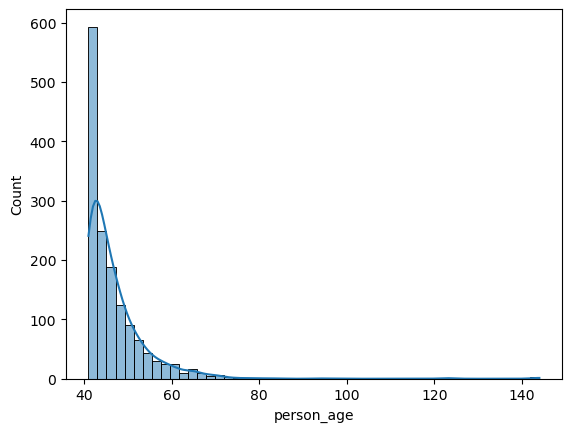

In [88]:
outliers = df[(df['person_age']>upper_border) | (df['person_age']<lower_border)]
print(len(outliers), len(df['person_age']), round(len(outliers)/len(df['person_age'])*100, 3))
#df['person_age'].sort_values(ascending=False).head(20)
sns.histplot(outliers['person_age'], bins = 50, kde = True)

In [94]:
outliers['person_age'].value_counts().sort_index()
#print((df['person_age']>100).sum()) всего пять значений больше сотни, хотя это и можно было увидеть визуально


person_age
41     241
42     188
43     164
44     141
45     108
46      94
47      94
48      75
49      49
50      52
51      39
52      36
53      30
54      24
55      20
56      15
57      15
58      19
59       5
60      15
61       9
62       7
63       3
64       7
65       9
66       9
67       1
69       5
70       7
73       3
76       1
78       1
80       1
84       1
94       1
123      2
144      3
Name: count, dtype: int64

In [107]:
df1 = df.copy()

In [108]:
def fix_age(person_age):
    if person_age >= 94:
        return 94
    else:
        return person_age

In [109]:
df1['person_age'] = df1['person_age'].apply(fix_age)

In [111]:
df1.max()
#видно, что person_emp_length ведет себя аномально

person_age                         94
person_income                 6000000
person_home_ownership            RENT
person_emp_length               123.0
loan_intent                   VENTURE
loan_grade                          G
loan_amnt                       35000
loan_int_rate                   23.22
loan_status                         1
loan_percent_income              0.83
cb_person_default_on_file           Y
cb_person_cred_hist_length         30
dtype: object

In [139]:
df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_status'].agg(['count', 'mean'])

/var/folders/fs/3wtwzm9n4sqdb8wjr4r8jbcm0000gn/T/ipykernel_5220/1300067037.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_status'].agg(['count', 'mean'])


,count,mean
person_age,,
"(0, 25]",15352,0.230263
"(25, 35]",13763,0.206786
"(35, 45]",2814,0.207178
"(45, 55]",513,0.218324
"(55, 65]",104,0.259615
"(65, 75]",25,0.200000
"(75, 100]",10,0.000000


In [140]:
df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_int_rate'].agg(['count', 'mean', 'median', 'min', 'max'])

/var/folders/fs/3wtwzm9n4sqdb8wjr4r8jbcm0000gn/T/ipykernel_5220/2350518532.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_int_rate'].agg(['count', 'mean', 'median', 'min', 'max'])


,count,mean,median,min,max
person_age,,,,,
"(0, 25]",13905,10.969802,10.99,5.42,22.11
"(25, 35]",12464,11.023724,10.99,5.42,22.48
"(35, 45]",2520,11.177667,11.12,5.42,23.22
"(45, 55]",452,11.028164,10.99,5.42,20.62
"(55, 65]",94,11.088617,10.99,5.42,18.64
"(65, 75]",22,11.178636,10.62,5.42,17.49
"(75, 100]",8,10.510000,10.98,7.51,13.57


In [158]:
#переходим к ставке loan_int_rate, мною было замечено, что есть пропуски NaN, осталось выяснить, что с ними делать
#df1[df1['loan_int_rate'].isnull()]
df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_int_rate'].agg(['count', 'mean', 'median', 'min', 'max'])

/var/folders/fs/3wtwzm9n4sqdb8wjr4r8jbcm0000gn/T/ipykernel_5220/1928660664.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_int_rate'].agg(['count', 'mean', 'median', 'min', 'max'])


,count,mean,median,min,max
person_age,,,,,
"(0, 25]",13905,10.969802,10.99,5.42,22.11
"(25, 35]",12464,11.023724,10.99,5.42,22.48
"(35, 45]",2520,11.177667,11.12,5.42,23.22
"(45, 55]",452,11.028164,10.99,5.42,20.62
"(55, 65]",94,11.088617,10.99,5.42,18.64
"(65, 75]",22,11.178636,10.62,5.42,17.49
"(75, 100]",8,10.510000,10.98,7.51,13.57


In [159]:
df1 = df1.dropna(subset = ['loan_int_rate']).copy()

In [181]:
#также ранее подмечал об экстремально большом опыте работы в person_emp_length
#df1[df1['person_emp_length'].notnull()].sort_values(by=['person_emp_length'], ascending=False)
#df1['person_emp_length'].sort_values(ascending=False)
#print((df1['person_emp_length'].isnull()).sum())

q1_person_emp_length = df1['person_emp_length'].quantile(0.25)
q3_person_emp_length = df1['person_emp_length'].quantile(0.75)

iqr_person_emp_length = q3_person_emp_length-q1_person_emp_length
upper_border_person_emp_length = q3_person_emp_length+1.5*iqr_person_emp_length
lower_border_person_emp_length = q1_person_emp_length-1.5*iqr_person_emp_length

print(q1_person_emp_length, q3_person_emp_length, iqr_person_emp_length, upper_border_person_emp_length, lower_border_person_emp_length)

2.0 7.0 5.0 14.5 -5.5


<Axes: ylabel='person_emp_length'>

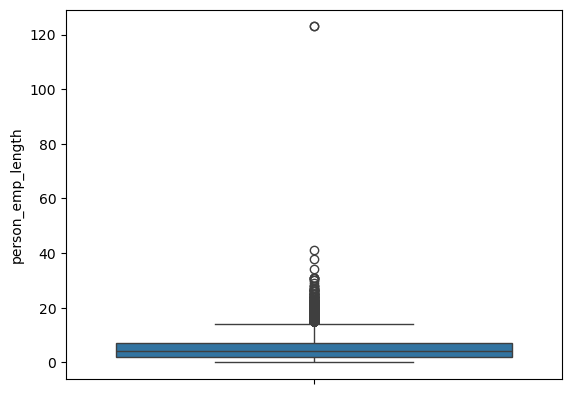

In [179]:
sns.boxplot(df['person_emp_length'])

In [201]:
#df1[df1['person_emp_length']>=df1['person_age']]
df1['diff'] = df1['person_age']-df1['person_emp_length']
#df1[df1['diff']>30]
# решил заменить аномальные значения 123 на среднее для этой же возрастной группы. кстати, среднее рассчитывал без учета 123 

mean_emp_length = df1.loc[(df1['person_age'] <= 25) & (df1['person_emp_length'] != 123), 'person_emp_length'].mean()
print(mean_emp_length)
#df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['person_emp_length'].agg(['count', 'mean', 'median', 'max'])
df1.loc[df1['person_emp_length'] == 123, 'person_emp_length'] = round(mean_emp_length)

4.0292263185223645


In [202]:
df1.sort_values(by=['person_emp_length'], ascending=False)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,diff
32355,78,48000,RENT,41.0,MEDICAL,A,3000,7.51,0,0.06,N,25,37.0
32515,53,106000,MORTGAGE,38.0,PERSONAL,B,20000,9.88,0,0.19,N,23,15.0
32428,58,49000,MORTGAGE,34.0,MEDICAL,D,7500,13.55,1,0.15,Y,24,24.0
30914,48,70000,MORTGAGE,31.0,HOMEIMPROVEMENT,D,9000,14.54,0,0.13,N,17,17.0
32263,46,180000,MORTGAGE,31.0,MEDICAL,B,18000,9.91,0,0.10,N,12,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32285,38,12000,OWN,NaN,EDUCATION,A,4800,7.29,1,0.40,N,12,NaN
32328,51,18408,RENT,NaN,PERSONAL,C,1000,14.65,1,0.05,Y,20,NaN
32360,70,39996,RENT,NaN,MEDICAL,C,3600,15.23,0,0.09,Y,19,NaN
32453,56,32400,RENT,NaN,MEDICAL,A,8575,7.51,0,0.26,N,18,NaN
